# Simple MLP Layer Comparison

In this notebook, we test a **multilayer perceptron (MLP)** with different numbers of hidden layers.

The goal is simple:
- build a clear MLP
- compare 1, 2, and 3 hidden layers
- plot loss and accuracy
- draw decision boundaries

We keep the code short and easy to understand.

## 1. Prepare the data

We use a simple non-linear dataset (`make_circles`) because it is a good example where a neural network is useful.

We also standardize the data before training.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_circles
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
import torch.optim as optim

np.random.seed(42)
torch.manual_seed(42)

# Create a simple binary classification dataset
X, y = make_circles(n_samples=800, noise=0.08, factor=0.35, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_s, dtype=torch.float32)
y_train_t = torch.tensor(y_train.reshape(-1, 1), dtype=torch.float32)
X_test_t = torch.tensor(X_test_s, dtype=torch.float32)
y_test_t = torch.tensor(y_test.reshape(-1, 1), dtype=torch.float32)

plt.figure(figsize=(5, 5))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap='RdBu', edgecolors='k', s=20)
plt.title('Dataset')
plt.xlabel('x1')
plt.ylabel('x2')
plt.show()

## 2. Build a simple MLP

We create one function to build the network.

We only change one thing between models: the **number of hidden layers**.

In all models:
- activation function: `ReLU`
- output: 1 neuron for binary classification
- loss: `BCEWithLogitsLoss`
- optimizer: `Adam`

In [ ]:
def build_mlp(input_dim, hidden_layers):
    layers = []
    in_dim = input_dim

    for hidden_dim in hidden_layers:
        layers.append(nn.Linear(in_dim, hidden_dim))
        layers.append(nn.ReLU())
        in_dim = hidden_dim

    layers.append(nn.Linear(in_dim, 1))
    return nn.Sequential(*layers)


def train_model(model, X_train, y_train, X_test, y_test, epochs=500, lr=0.01):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {
        'train_loss': [],
        'train_acc': [],
        'test_loss': [],
        'test_acc': []
    }

    for _ in range(epochs):
        model.train()
        train_logits = model(X_train)
        train_loss = criterion(train_logits, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            train_probs = torch.sigmoid(train_logits)
            train_preds = (train_probs >= 0.5).float()
            train_acc = (train_preds == y_train).float().mean().item()

            test_logits = model(X_test)
            test_loss = criterion(test_logits, y_test)
            test_probs = torch.sigmoid(test_logits)
            test_preds = (test_probs >= 0.5).float()
            test_acc = (test_preds == y_test).float().mean().item()

        history['train_loss'].append(train_loss.item())
        history['train_acc'].append(train_acc)
        history['test_loss'].append(test_loss.item())
        history['test_acc'].append(test_acc)

    return history

## 3. Try different numbers of hidden layers

We use the same hidden size (`16`) and only change the depth:
- 1 hidden layer: `[16]`
- 2 hidden layers: `[16, 16]`
- 3 hidden layers: `[16, 16, 16]`

This makes the comparison easy and fair.

In [ ]:
configs = {
    '1 hidden layer': [16],
    '2 hidden layers': [16, 16],
    '3 hidden layers': [16, 16, 16]
}

results = {}
models = {}

for name, hidden_layers in configs.items():
    torch.manual_seed(42)
    model = build_mlp(input_dim=2, hidden_layers=hidden_layers)
    history = train_model(model, X_train_t, y_train_t, X_test_t, y_test_t, epochs=500, lr=0.01)

    results[name] = history
    models[name] = model

    print(name)
    print('  hidden layers :', hidden_layers)
    print('  activation    : ReLU')
    print('  final test acc:', round(history['test_acc'][-1], 4))
    print()

## 4. Plot loss and accuracy

These plots help us see if the model learns well.

Quick idea:
- lower loss is better
- higher accuracy is better
- if train and test curves stay close, the model generalizes better

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, history in results.items():
    axes[0].plot(history['test_loss'], label=name)
    axes[1].plot(history['test_acc'], label=name)

axes[0].set_title('Test Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].grid(alpha=0.3)
axes[0].legend()

axes[1].set_title('Test Accuracy')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

### Quick analysis

After running the curves:
- if one model reaches good accuracy faster, it learns more efficiently
- if a deeper model performs better, extra layers help learn the non-linear shape
- if all models are similar, then the problem may already be simple enough for a shallow network

## 5. Draw the decision boundaries

This lets us see how each model separates the two classes in the plane.

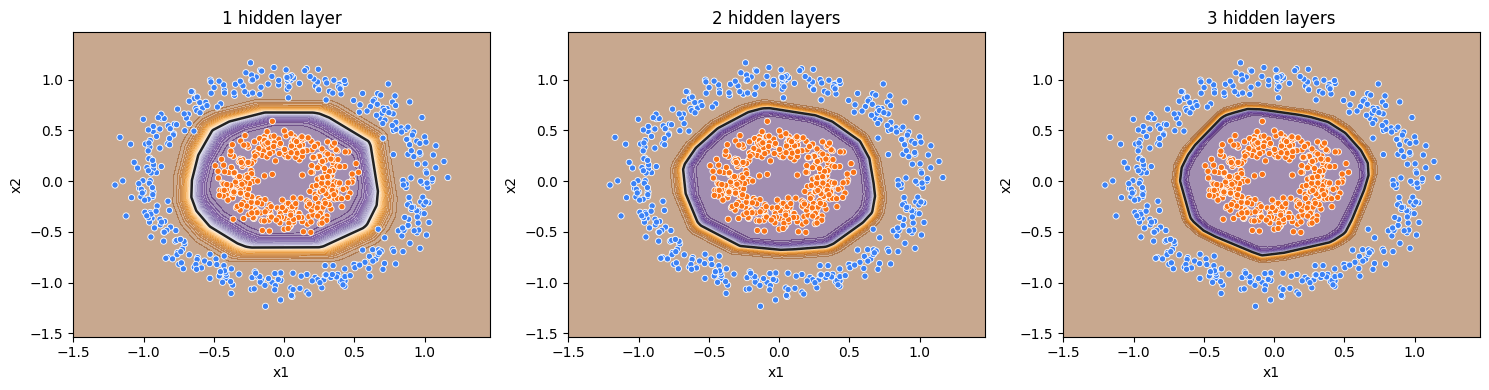

In [9]:
from matplotlib.colors import ListedColormap


def plot_boundary(ax, model, X_raw, y_raw, scaler, title):
    x_min, x_max = X_raw[:, 0].min() - 0.3, X_raw[:, 0].max() + 0.3
    y_min, y_max = X_raw[:, 1].min() - 0.3, X_raw[:, 1].max() + 0.3

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    grid_s = scaler.transform(grid)

    model.eval()
    with torch.no_grad():
        grid_t = torch.tensor(grid_s, dtype=torch.float32)
        probs = torch.sigmoid(model(grid_t)).numpy().reshape(xx.shape)

    background_cmap = 'PuOr'
    point_cmap = ListedColormap(['#3B82F6', '#F97316'])

    ax.contourf(xx, yy, probs, levels=40, cmap=background_cmap, alpha=0.45)
    ax.contour(xx, yy, probs, levels=[0.5], colors='#222222', linewidths=1.8)
    ax.scatter(X_raw[:, 0], X_raw[:, 1], c=y_raw, cmap=point_cmap, edgecolors='white', linewidths=0.6, s=20)
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')


fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, model) in zip(axes, models.items()):
    plot_boundary(ax, model, X, y, scaler, name)

plt.tight_layout()
plt.show()

## 6. Final summary

What we did:
- trained simple MLP models with different numbers of hidden layers
- compared their loss and accuracy
- visualized their decision boundaries

What we learn:
- a multilayer perceptron can learn non-linear patterns
- changing the number of layers changes the model capacity
- sometimes a simple model is enough, and sometimes a deeper model gives a better boundary